In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'BRFS3.SA'
papeis_adicionais = ['MRFG3.SA', 'BEEF3.SA', 'ASAI3.SA', 'CRFB3.SA']

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() #- timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
#df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[BRFS3.SA] Cache existente cobre de 2020-01-02 a 2025-07-14.
[BRFS3.SA] Cache NÃO cobre período solicitado. Download total necessário.
[BRFS3.SA] Iniciando download de dados (lógica de atualização/complemento)...
[BRFS3.SA] Período de download yfinance: 2020-01-01 a 2025-07-19
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[BRFS3.SA] Realizando verificação de divergência entre cache antigo e dados frescos...
[BRFS3.SA] Pós-Download Total: Nenhuma divergência significativa nas amostras (tolerância 1.00%).
[BRFS3.SA] Cache principal ATUALIZADO com dados frescos: /palpiteiro/dados\BRFS3.csv
[BRFS3.SA] Retornando 613 linhas para o período solicitado.
✅ Usando cache local: /palpiteiro/dados\macro_20220127_20250716.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-07-15.
[^BVSP] Cache cobre período solicitado (2023-01-27 a 2025-07-15).
[^BVSP] Garantindo atualização dos últimos 5 dias do cach

,open,high,low,close,adj_close,volume,pct_change,vol,rsi,macd,macd_signal,macd_hist,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,adj_close_ibov,volume_ibov
data,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-07-02,20.00,20.010000,19.620001,19.620001,19.620001,3999800,-0.019000,0.027072,40.345104,-0.217946,-0.093206,-0.124739,0.389999,0.805007,0.041030,0.019878,19.952,20.6030,15.0,0.26,5.4512,139586.00000,140049.000000,138384.0000,139051.0000,139051.0000,3619807
2025-07-03,19.67,19.740000,19.190001,19.190001,19.190001,5200700,-0.021916,0.026053,36.919357,-0.289524,-0.132470,-0.157054,0.549999,0.786792,0.041000,0.028661,19.770,20.5375,15.0,0.26,5.4208,139051.00000,141304.000000,139051.0000,140928.0000,140928.0000,3879378
2025-07-04,19.15,19.850000,18.860001,19.850000,19.850000,6228600,0.034393,0.029366,44.683271,-0.289655,-0.163907,-0.125748,0.990000,0.801307,0.040368,0.049874,19.760,20.5050,15.0,0.26,5.4090,140928.00000,141537.000000,140597.0000,141478.0000,141478.0000,5528911
2025-07-07,19.75,21.709999,19.620001,21.709999,21.709999,22466700,0.093703,0.040196,59.726914,-0.138080,-0.158741,0.020661,2.089998,0.893356,0.041150,0.096269,20.074,20.5645,15.0,0.26,5.4552,141265.00000,141342.000000,139295.0000,139490.0000,139490.0000,3691359
2025-07-08,21.50,22.190001,21.330000,22.129999,22.129999,24078300,0.019346,0.036918,62.225081,0.015753,-0.123843,0.139595,0.860001,0.890973,0.040261,0.038861,20.500,20.6210,15.0,0.26,5.4571,139491.00000,139591.000000,138770.0000,139303.0000,139303.0000,2574588
2025-07-09,22.07,23.170000,21.480000,22.500000,22.500000,50158600,0.016719,0.033765,64.324571,0.165613,-0.065951,0.231564,1.690001,0.948047,0.042135,0.075111,21.076,20.6705,15.0,0.26,5.4626,139303.00000,139331.000000,137299.0000,137481.0000,137481.0000,8538960
2025-07-10,21.90,23.150000,21.610001,23.000000,23.000000,38802600,0.022222,0.033776,66.994209,0.321024,0.011444,0.309580,1.539999,0.990329,0.043058,0.066956,21.838,20.7525,15.0,0.26,5.5433,137472.00000,137472.000000,136015.0000,136743.0000,136743.0000,5335029
2025-07-11,22.74,22.830000,21.860001,22.000000,22.000000,11190500,-0.043478,0.037843,57.695184,0.359354,0.081026,0.278328,1.139999,1.001020,0.045501,0.051818,22.268,20.8180,15.0,0.26,5.5722,136742.00000,136742.000000,135528.0000,136187.0000,136187.0000,4964400
2025-07-14,21.92,21.930000,20.559999,21.000000,21.000000,11004200,-0.045455,0.041781,50.192395,0.305517,0.125924,0.179593,1.440001,1.032376,0.049161,0.068571,22.126,20.8180,15.0,0.26,5.5595,136187.00000,136187.000000,134840.0000,135299.0000,135299.0000,4839858


## Verificação da volatilidade recente

In [7]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-07-02,0.805007,0.041030,0.389999,0.019878
2025-07-03,0.786792,0.041000,0.549999,0.028661
2025-07-04,0.801307,0.040368,0.990000,0.049874
2025-07-07,0.893356,0.041150,2.089998,0.096269
2025-07-08,0.890973,0.040261,0.860001,0.038861
2025-07-09,0.948047,0.042135,1.690001,0.075111
2025-07-10,0.990329,0.043058,1.539999,0.066956
2025-07-11,1.001020,0.045501,1.139999,0.051818
2025-07-14,1.032376,0.049161,1.440001,0.068571


In [8]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 4.77%
Valorização sugerida: 7.15%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [11]:
valorizacao = 0.07
stop_loss = 0.05
DIAS_FUTURO = 3   # dias futuros para buscar a valorização

In [12]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

#0.0    0.789474
#1.0    0.210526

Target
0.0    0.813115
1.0    0.186885
Name: proportion, dtype: float64

In [ ]:
# estudo de qual tamanho de janela é melhor para este papel
tamanhos_janela = [6, 10, 15, 20, 30, 60]
lista_f1_treino = []
lista_f1_validacao = []
lista_pr_auc_treino = []
lista_pr_auc_validacao = []

for tamanho_janela in tamanhos_janela:
    X, y = pp.preparar_X_y_agregado(df, tamanho_janela, dropna=True, tipo_drop_na='linhas')   

    X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)
    X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
    X_validacao = X_validacao[X_train.columns]

    modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
    modelo.fit(X_train.values, y_train.values)

    roc_treino, roc_validacao, diferenca, pr_auc_treino, pr_auc_validacao, f1_score_treino, f1_score_validacao = tr.comparar_auc_conjuntos(modelo, X_train, y_train, X_validacao, y_validacao)

    lista_f1_treino.append(f1_score_treino)
    lista_f1_validacao.append(f1_score_validacao)

    lista_pr_auc_treino.append(pr_auc_treino)
    lista_pr_auc_validacao.append(pr_auc_validacao)

df_resultados = pd.DataFrame({
    'Tamanho Janela': tamanhos_janela,
    'F1 Treino': lista_f1_treino,
    'F1 Validação': lista_f1_validacao,
    'PR AUC Treino': lista_pr_auc_treino,
    'PR AUC Validação': lista_pr_auc_validacao
})

In [12]:
df_resultados.sort_values(by='PR AUC Validação', ascending=False)

,Tamanho Janela,F1 Treino,F1 Validação,PR AUC Treino,PR AUC Validação
5,60,0.301670,0.605328,0.389973,0.603054
4,30,0.325975,0.394661,0.410528,0.503651
1,10,0.349994,0.390077,0.499900,0.437812
0,6,0.324094,0.403436,0.410058,0.428917
2,15,0.310922,0.268651,0.517382,0.345426
3,20,0.347097,0.322746,0.448777,0.331132


In [13]:
# Preparar X e y para treino
DIAS_JANELA_X = 10  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True, tipo_drop_na='linhas')   

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

INFO: 25 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


In [14]:
X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
X_validacao = X_validacao[X_train.columns]
print("Features removidas por alta correlação:", removidas)
print(f"Colunas restantes após filtragem: {X_train.shape[1]}")

Features removidas por alta correlação: ['close_amplitude', 'close_amplitude_norm_atr_principal', 'close_max', 'macd_ultimo_norm_atr_principal', 'dias_queda_pct', 'macd_hist_ultimo_norm_atr_principal', 'close_min', 'macd_mean', 'macd_signal_ultimo', 'macd_signal_mean', 'ibov_std']
Colunas restantes após filtragem: 54


In [15]:
X_train.tail()

,close_mean,close_std,close_trend,retorno_desde_mudanca_close,close_dist_min,close_ult_vs_mm_janela,close_vs_mm20,mm5_vs_mm20,retorno_mean,retorno_std,retorno_acumulado,dias_alta_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,atr_pct_ultimo,rsi_mean,rsi_std,rsi_ultimo,macd_std,macd_ultimo,macd_signal_std,macd_hist_mean,macd_hist_std,macd_hist_ultimo,tr_mean,tr_std,tr_ultimo,tr_pct_mean,tr_pct_std,tr_pct_ultimo,selic_ultimo,ipca_ultimo,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,retorno_desde_mudanca_ibov,ibov_amplitude,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean,atr_ultimo,macd_std_norm_atr_principal,macd_signal_std_norm_atr_principal,macd_signal_ultimo_norm_atr_principal,macd_hist_std_norm_atr_principal,tr_std_norm_atr_principal,tr_ultimo_norm_atr_principal,close_std_norm_atr_principal
2025-02-20,19.924,0.886469,-0.268848,-0.040471,0.000000,-1.194000,-0.099324,-0.072011,-0.011893,0.024878,-0.092539,0.2,0.031324,-0.022698,6860440.0,2.716375e+06,97341.818182,-0.107186,0.040216,32.277175,3.773618,27.997023,0.088120,-1.128502,0.041463,-0.045114,0.049889,-0.107244,0.740,0.235843,0.469999,0.036967,0.011288,0.025093,13.25,0.16,5.7019,-0.009853,0.035094,0.000000,399.290909,0.000000,4489.0,0.652110,1.376200,-0.014146,0.753236,0.116989,0.055046,-1.355828,0.066233,0.313107,0.623973,1.176880
2025-02-21,19.760,0.890979,-0.271515,0.000000,0.270000,-0.760000,-0.079970,-0.075418,-0.007948,0.025678,-0.110070,0.3,0.025688,-0.022364,6879460.0,2.698104e+06,-186361.212121,-0.327782,0.038316,32.311518,3.762107,31.329458,0.096397,-1.123173,0.050893,-0.050408,0.050743,-0.081531,0.707,0.259317,0.400002,0.035535,0.012369,0.021053,13.25,0.16,5.7027,-0.010992,0.036638,0.000000,290.290909,0.000000,4489.0,0.575020,1.037899,-0.014144,0.728005,0.132412,0.069907,-1.430816,0.069701,0.356202,0.549449,1.223864
2025-02-24,19.495,0.748172,-0.223333,0.000000,0.000000,-0.794999,-0.086468,-0.075232,-0.012967,0.020951,-0.112061,0.2,0.021332,-0.021542,6871650.0,2.703428e+06,-387222.424242,-0.246265,0.038900,31.340357,2.879821,29.685481,0.095144,-1.130130,0.058136,-0.059300,0.044848,-0.070790,0.688,0.249568,0.719999,0.035123,0.012174,0.038503,13.25,0.16,5.7258,-0.008556,0.033116,0.004051,120.212121,-0.013585,4489.0,0.564770,0.966707,-0.012015,0.727433,0.130795,0.079919,-1.456269,0.061652,0.343080,0.989780,1.028509
2025-02-25,19.275,0.527873,-0.153636,0.000000,0.160000,-0.415000,-0.071531,-0.071334,-0.010753,0.022021,-0.067721,0.3,0.017073,-0.022679,7089750.0,2.722357e+06,-361537.575758,0.168320,0.038125,30.775375,1.971508,31.742679,0.078830,-1.109937,0.060860,-0.066973,0.031157,-0.040479,0.683,0.250690,0.609999,0.035224,0.012143,0.032344,13.25,0.16,5.7779,-0.002744,0.032971,0.013187,47.121212,0.000000,4489.0,0.459058,0.824243,-0.008789,0.719045,0.109632,0.084640,-1.487332,0.043332,0.348642,0.848345,0.734130
2025-02-26,19.153,0.410584,-0.104424,0.007953,0.309999,-0.143000,-0.057137,-0.064577,-0.006017,0.020189,-0.023626,0.4,0.014793,-0.019890,7325660.0,2.792909e+06,-271568.484848,0.246236,0.037903,30.913147,2.133208,33.701042,0.058123,-1.069503,0.058309,-0.067073,0.030914,-0.000035,0.661,0.232687,0.740000,0.034371,0.011470,0.038927,13.25,0.16,5.7757,0.002445,0.033628,0.000000,-228.254545,0.000000,4100.0,0.489482,0.724848,-0.002505,0.720542,0.080666,0.080923,-1.484254,0.042904,0.322933,1.027004,0.569826


# LogisticRegression

In [17]:
modelo_rl = LogisticRegression(solver='liblinear', penalty='l2', random_state=42, class_weight='balanced', C=0.01)
modelo_rl.fit(X_train, y_train)
tr.comparar_auc_conjuntos(modelo_rl, X_train, y_train, X_validacao, y_validacao)

AUC no treino: 0.504
AUC na validação: 0.497
Diferença AUC (Treino - Validação): 0.006
PR AUC no treino: 0.297
PR AUC na validação: 0.353
Diferença PR AUC (Treino - Validação): -0.056
F1 Score no treino: 0.301
F1 Score na validação: 0.186


(np.float64(0.5035997007234786),
 np.float64(0.49729974800638155),
 np.float64(0.006299952717097046),
 np.float64(0.29658955823596617),
 np.float64(0.3528923971445778),
 np.float64(0.30093099408971746),
 np.float64(0.18550801546883758))

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: b005040032254cb0ad44843f0f2e4a4b para BRFS3.SA_10dias_x_0.07val_3dias_alvo
AUC no treino: 0.621
AUC na validação: 0.360

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.504
  Precisão média (em 457 janelas com previsão positiva): 0.182
  Recall médio: 0.641

Calibrando thresholds para precisão mínima de 0.55...
Nenhum threshold atendeu à precisão mínima de 0.55. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.117
Recall médio: 0.383
Sinais de compra presentes na vallidação: 15.0
Sinais de compra previstos na validação: 30
Modelo BRFS3.SA_10dias_x_0.07val_3dias_alvo salvo na run b005040032254cb0ad44843f0f2e4a4b


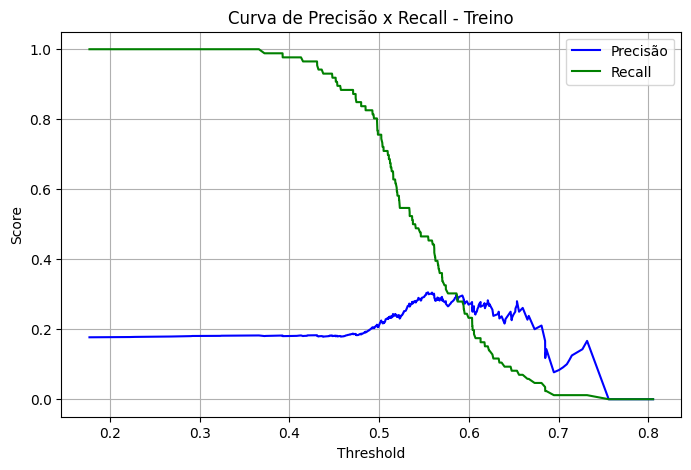

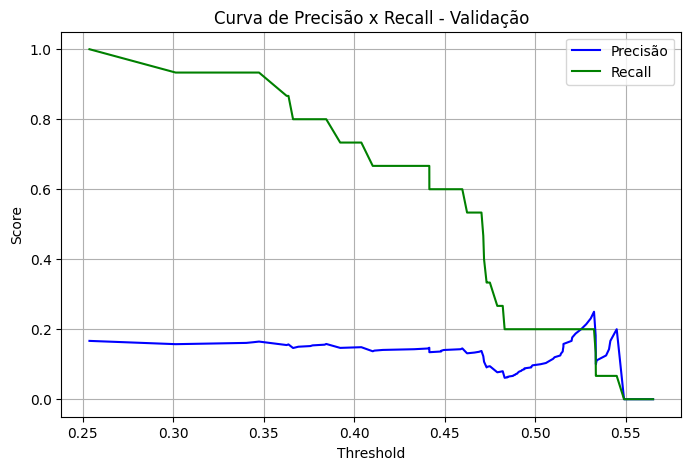

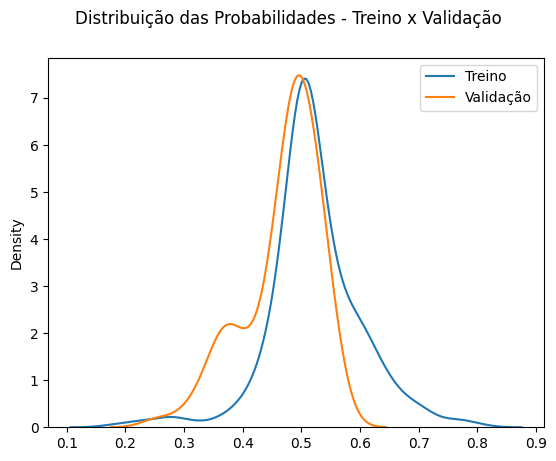

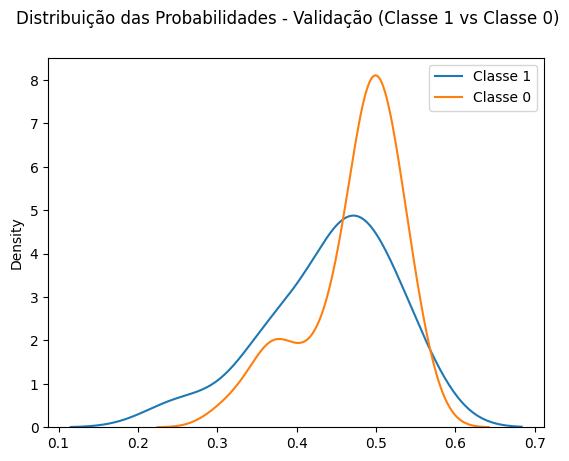

In [19]:
recall_minimo = None
precisao_minima = 0.55
resultado = tr.avaliar_e_logar_modelo(modelo_rl, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

In [18]:
# Importâncias
importancias = pd.Series(modelo_rl.coef_[0], index=X_train.columns)
df_importancias = pd.DataFrame({
    'Feature': importancias.index,
    'importancia': importancias.values,
    'importancia_abs': importancias.abs().values
})
df_importancias.sort_values(by='importancia_abs', ascending=False, inplace=True)
df_importancias.head(15)


,Feature,importancia,importancia_abs
20,rsi_ultimo,0.000943,0.000943
36,ibov_trend,-0.000932,0.000932
18,rsi_mean,0.000581,0.000581
30,selic_ultimo,0.000450,0.000450
37,ibov_std,-0.000406,0.000406
19,rsi_std,0.000265,0.000265
0,close_mean,0.000135,0.000135
32,dolar_ultimo,0.000053,0.000053
40,beta_papel_ibov,-0.000050,0.000050
4,close_dist_min,0.000029,0.000029


In [19]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k)['Feature'].tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight={0:1, 1:2})
            modelo.fit(X_train[colunas_selecionadas], y_train )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, df_importancias)

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


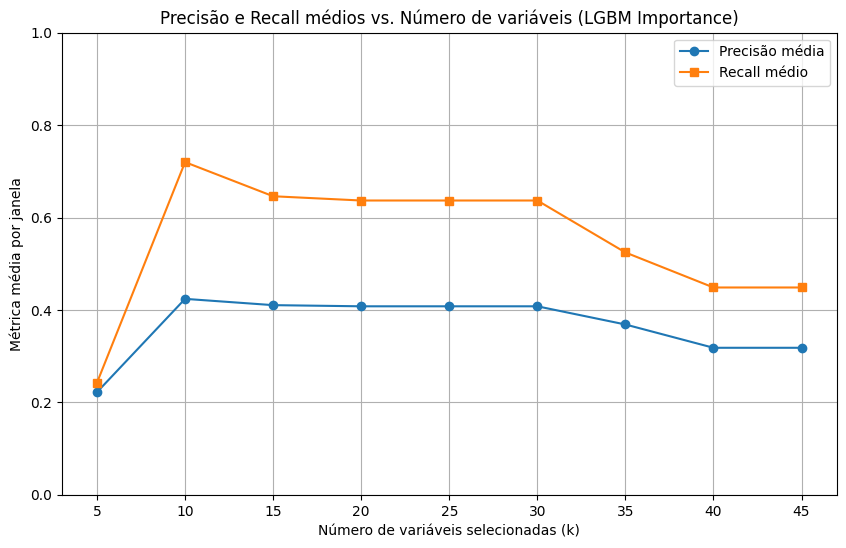

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (LGBM Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [25]:
n_features = 30
lista_colunas_selecionadas = df_importancias.head(n_features)['Feature'].tolist()
lista_colunas_selecionadas

['rsi_ultimo',
 'ibov_trend',
 'rsi_mean',
 'selic_ultimo',
 'ibov_std',
 'rsi_std',
 'close_mean',
 'dolar_ultimo',
 'beta_papel_ibov',
 'close_dist_min',
 'close_ult_vs_mm_janela',
 'tr_mean',
 'atr_ultimo',
 'macd_hist_ultimo_norm_atr_principal',
 'macd_signal_mean',
 'tr_ultimo',
 'macd_signal_ultimo_norm_atr_principal',
 'tr_ultimo_norm_atr_principal',
 'close_trend',
 'macd_signal_std_norm_atr_principal',
 'close_std',
 'macd_hist_mean',
 'macd_hist_std_norm_atr_principal',
 'close_std_norm_atr_principal',
 'macd_hist_std',
 'tr_std',
 'macd_std_norm_atr_principal',
 'close_vs_mm20',
 'dias_alta_pct',
 'dolar_trend']

In [26]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [27]:
modelo_rl_reduzido = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', C=0.01)
modelo_rl_reduzido.fit(X_train_reduzido, y_train)
tr.comparar_auc_conjuntos(modelo_rl_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.716
AUC na validação: 0.491
Diferença AUC (Treino - Validação): 0.225
PROVÁVEL OVERFITTING
PR AUC no treino: 0.508
PR AUC na validação: 0.399
Diferença PR AUC (Treino - Validação): 0.109
F1 Score no treino: 0.412
F1 Score na validação: 0.537


(np.float64(0.7161286553270275),
 np.float64(0.4912638632695808),
 np.float64(0.2248647920574467),
 np.float64(0.5079867563536535),
 np.float64(0.3990728863006694),
 np.float64(0.4120553986720636),
 np.float64(0.5368486570249914))

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: 14cf0efb01aa4bfea9366f639db9d34c para CSAN3.SA_10dias_x_0.07val_7dias_alvo
AUC no treino: 0.828
AUC na validação: 0.415

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.716
  Precisão média (em 425 janelas com previsão positiva): 0.309
  Recall médio: 0.458

Calibrando thresholds para precisão mínima de 0.70...

Threshold Ideal Selecionado: 0.67
  Precisão Média Esperada: 74.65%
  Recall Médio Esperado: 17.61%
  Janelas Usadas para Precisão: 180.0

Threshold ideal baseado em mínimo recall ou precisão: 0.67

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.401
Recall médio: 0.569
Sinais de compra presentes na vallidação: 28.0
Sinais de compra previstos na validação: 56
Modelo CSAN3.SA_10dias_x_

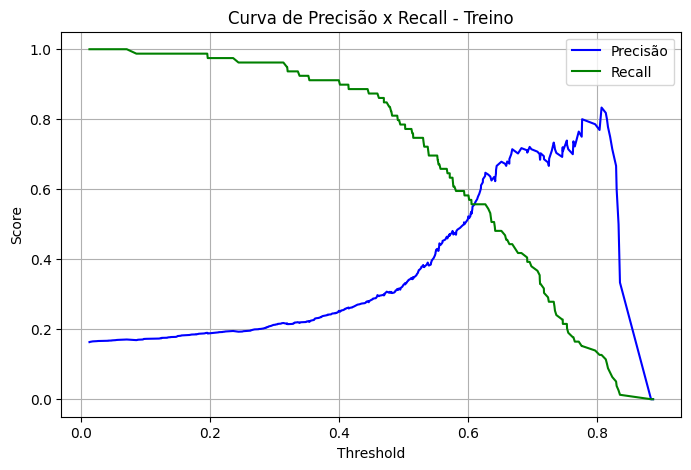

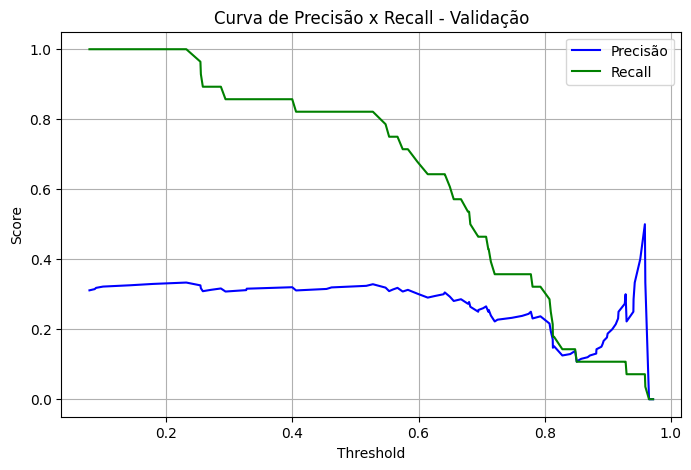

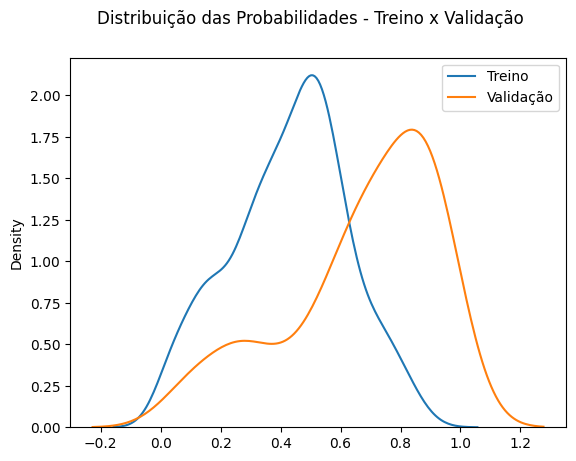

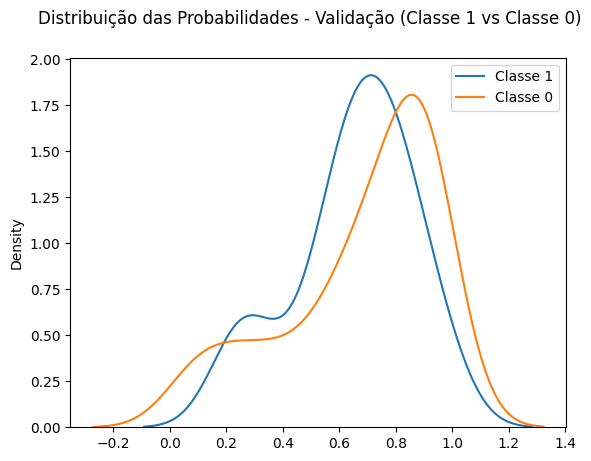

In [28]:
recall_minimo = None
precisao_minima = 0.7
resultado = tr.avaliar_e_logar_modelo(modelo_rl_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# LGBM GOOGLE

## Versão com early stopping

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit # Para o CV interno da calibração, se optar por essa via
from sklearn.metrics import roc_auc_score
import lightgbm as lgbm # Para o callback de early stopping
from sklearn.frozen import FrozenEstimator

def criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo: pd.DataFrame, # Seus 510 dias
        y_super_treino_completo: pd.Series,
        fracao_eval_es: float = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params: dict = None,
        early_stopping_rounds_lgbm: int = 50,
        eval_metric_lgbm: str = 'auc',
        calibrar_modelo: bool = True,
        metodo_calibracao: str = 'isotonic',
        # Opção A para calibração: usar o mesmo eval_set_es para cv='prefit'
        # Opção B para calibração: usar TimeSeriesSplit no X_treino_base_lgbm para cv do CalibratedCV
        estrategia_calibracao_cv = 'prefit' # ou um objeto TimeSeriesSplit(n_splits=3)
        , class_weight: str = 'balanced' 
    ):
    """
    Treina o modelo final (LGBM) usando uma parte do X_super_treino_completo para treino
    e outra parte para early stopping. Opcionalmente calibra o modelo.

    Retorna o modelo final treinado (e possivelmente calibrado).
    """
    if not (0 < fracao_eval_es < 1):
        raise ValueError("fracao_eval_es deve estar entre 0 e 1 (exclusivo).")

    n_total_super_treino = len(X_super_treino_completo)
    n_eval_es = int(n_total_super_treino * fracao_eval_es)
    n_treino_base_lgbm = n_total_super_treino - n_eval_es

    if n_treino_base_lgbm < 50 or n_eval_es < 20: # Mínimos arbitrários, ajuste conforme necessário
        raise ValueError(f"Dados insuficientes no X_super_treino para o split de early stopping. "
                         f"Treino Base: {n_treino_base_lgbm}, Eval ES: {n_eval_es}")

    X_treino_base_lgbm = X_super_treino_completo.iloc[:n_treino_base_lgbm]
    y_treino_base_lgbm = y_super_treino_completo.iloc[:n_treino_base_lgbm]
    X_eval_set_es = X_super_treino_completo.iloc[n_treino_base_lgbm:]
    y_eval_set_es = y_super_treino_completo.iloc[n_treino_base_lgbm:]

    print(f"Dividindo Super Treino ({n_total_super_treino} amostras):")
    print(f"  - Treino Base LGBM: {len(X_treino_base_lgbm)} amostras")
    print(f"  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): {len(X_eval_set_es)} amostras")

    # --- 1. Treinar LGBM com Early Stopping ---
    if lgbm_params is None:
        lgbm_params = {
            'n_estimators': 1000, 'learning_rate': 0.01, 'num_leaves': 8,
            'max_depth': 3, 'min_child_samples': 20, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1,
            'class_weight': class_weight,
            'importance_type': 'gain', 
            'verbose': -1 # Desativa logs do LGBM

        }

    modelo_lgbm = LGBMClassifier(**lgbm_params)
    print(f"\nIniciando treinamento LGBM com early stopping (monitorando '{eval_metric_lgbm}')...")

    # Certificar que X_treino_base_lgbm.values e X_eval_set_es.values são usados se as funções esperam arrays
    # Se X são DataFrames, LGBM geralmente lida bem, mas para consistência com sklearn:
    X_treino_lgbm_arr = X_treino_base_lgbm.values if isinstance(X_treino_base_lgbm, pd.DataFrame) else X_treino_base_lgbm
    y_treino_lgbm_arr = y_treino_base_lgbm.values if isinstance(y_treino_base_lgbm, pd.Series) else y_treino_base_lgbm
    X_eval_es_arr = X_eval_set_es.values if isinstance(X_eval_set_es, pd.DataFrame) else X_eval_set_es
    y_eval_es_arr = y_eval_set_es.values if isinstance(y_eval_set_es, pd.Series) else y_eval_set_es

    modelo_lgbm.fit(
        X_treino_lgbm_arr, y_treino_lgbm_arr,
        eval_set=[(X_eval_es_arr, y_eval_es_arr)],
        eval_metric=eval_metric_lgbm,
        callbacks=[lgbm.early_stopping(stopping_rounds=early_stopping_rounds_lgbm, verbose=10)]
    )
    print(f"Treinamento LGBM concluído. Melhor iteração: {modelo_lgbm.best_iteration_}")
    # Após o ES, o modelo_lgbm já está treinado com o número ótimo de árvores.

    if not calibrar_modelo:
        return modelo_lgbm # Retorna o LGBM treinado sem calibração

    # --- 2. Calibrar o Modelo Treinado ---
    print(f"\nCalibrando o LGBM treinado (método: {metodo_calibracao})...")
    
    

    if estrategia_calibracao_cv == "prefit":
        # Usa o X_eval_set_es para treinar o calibrador.
        # Este conjunto já foi "visto" para determinar n_estimators, então não é 100% puro
        # para calibração, mas é uma prática comum.
        print(f"  Usando conjunto de early stopping ({len(X_eval_set_es)} amostras) para treinar o calibrador (cv='prefit').")

        modelo_frozen = FrozenEstimator(modelo_lgbm) # Congela o modelo LGBM treinado com ES
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_frozen, # O modelo LGBM JÁ TREINADO com ES e congelado
            method=metodo_calibracao            
            )
        modelo_final_calibrado.fit(X_eval_es_arr, y_eval_es_arr)
    elif isinstance(estrategia_calibracao_cv, TimeSeriesSplit):
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_lgbm, # O modelo LGBM JÁ TREINADO com ES
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv # Pode ser "prefit" ou um objeto TimeSeriesSplit
            )
        # Treina o CalibratedClassifierCV no X_treino_base_lgbm.
        # O CalibratedCV irá internamente usar o LGBM (já com n_estimators ótimo)
        # e fazer cross-validation no X_treino_base_lgbm para ajustar o calibrador.
        # O estimador base (LGBM) NÃO é retreinado do zero pelo CalibratedCV se já tiver fit e cv='prefit'
        # MAS, se cv é um objeto splitter, ele *pode* retreinar o base_estimator em cada fold.
        # Para evitar retreinar o LGBM que já teve ES, a abordagem com 'prefit' é mais direta.
        # Se você quiser usar um splitter para o CV da calibração, é mais seguro
        # passar um LGBM *não treinado* para CalibratedCV, e o CalibratedCV fará o fit
        # do LGBM e do calibrador em seus folds internos. Mas aí você perde o ES global.
        
        # A maneira mais limpa se não usar 'prefit' para o CalibratedCV é
        # fazer com que ele treine um LGBM novo (sem ES global) em seus folds.
        # Ou, você pode fazer o ES em cada fold do CalibratedCV (mais complexo).

        # Simplificação: Se não for 'prefit', vamos assumir que você quer que o CalibratedCV
        # treine o LGBM base (com os params definidos) e o calibrador nos folds do X_treino_base_lgbm.
        # Isso ignora o `modelo_lgbm` treinado com ES anteriormente, a menos que
        # o `base_estimator` do CalibratedCV seja clonado e o `n_estimators` ótimo seja setado.
        # Vamos manter a lógica de 'prefit' como principal ou usar CV no conjunto de treino base.
        print(f"  Usando TimeSeriesSplit no Treino Base LGBM ({len(X_treino_base_lgbm)} amostras) para treinar o calibrador.")
        
        # Reinstanciar o LGBM com os parâmetros e n_estimators ótimos
        # para ser usado pelo CalibratedClassifierCV com seu próprio CV.
        # Isso garante que o n_estimators do ES seja usado em cada fold do CalibratedCV.
        params_lgbm_com_best_iter = modelo_lgbm.get_params()
        if hasattr(modelo_lgbm, 'best_iteration_') and modelo_lgbm.best_iteration_ is not None:
             params_lgbm_com_best_iter['n_estimators'] = modelo_lgbm.best_iteration_
        
        lgbm_para_calib_cv = LGBMClassifier(**params_lgbm_com_best_iter)

        modelo_final_calibrado_cv = CalibratedClassifierCV(
            lgbm_para_calib_cv,
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv
        )
        modelo_final_calibrado_cv.fit(X_treino_lgbm_arr, y_treino_lgbm_arr) # Treina no treino base
        print("Calibração com CV interno concluída.")
        return modelo_final_calibrado_cv # Retorna o modelo calibrado com CV
    else:
        raise ValueError(f"estrategia_calibracao_cv desconhecida: {estrategia_calibracao_cv}. Use 'prefit' ou um objeto TimeSeriesSplit.")

    print("Calibração concluída.")
    return modelo_final_calibrado, modelo_lgbm

In [ ]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.

# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado, modelo_original = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'
    #, class_weight={0:2.5, 1:1} # Ajuste conforme necessário
)
#modelo_treinado.fit(X_train.values, y_train.values)  # Fit final após calibração

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, X_train, y_train, X_validacao, y_validacao)

Dividindo Super Treino (485 amostras):
  - Treino Base LGBM: 388 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 97 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[13]	valid_0's auc: 0.714286	valid_0's binary_logloss: 0.635803
Treinamento LGBM concluído. Melhor iteração: 13

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (97 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.786
AUC na validação: 0.527
Diferença AUC (Treino - Validação): 0.260
PROVÁVEL OVERFITTING
PR AUC no treino: 0.467
PR AUC na validação: 0.435
Diferença PR AUC (Treino - Validação): 0.032
F1 Score no treino: 0.475
F1 Score na validação: 0.215


(np.float64(0.7862949773380108),
 np.float64(0.526668508748471),
 np.float64(0.25962646858953975),
 np.float64(0.46680228409528235),
 np.float64(0.43495651913598127),
 np.float64(0.47525495314198424),
 np.float64(0.21450849721612944))

Avaliar e logar modelo
MLflow Run ID: a3aa057e85394ce7accf3a2f66f0459c para MRFG3.SA_6dias_x_0.07val_5dias_alvo
AUC no treino: 0.768
AUC na validação: 0.572

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.786
  Precisão média (em 453 janelas com previsão positiva): 0.369
  Recall médio: 0.853

Calibrando thresholds para precisão mínima de 0.65...
Nenhum threshold atendeu à precisão mínima de 0.65. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 28 janelas com previsão positiva): 0.858
Recall médio: 0.174
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 15
Modelo MRFG3.SA_6dias_x_0.07val_5dias_alvo salvo na run a3aa057e85394ce7accf3a2f66f0459c


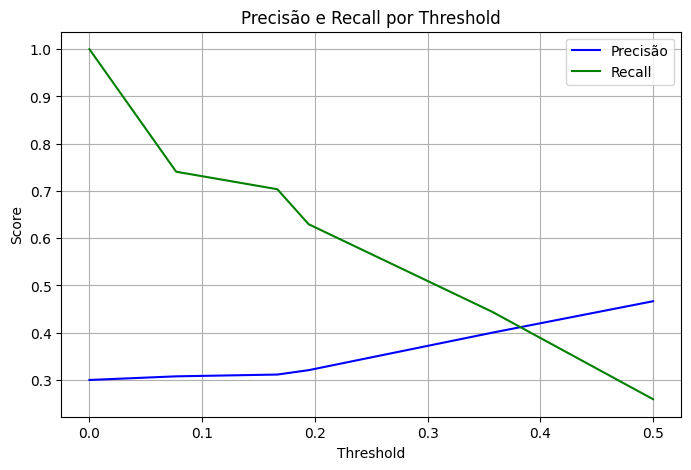

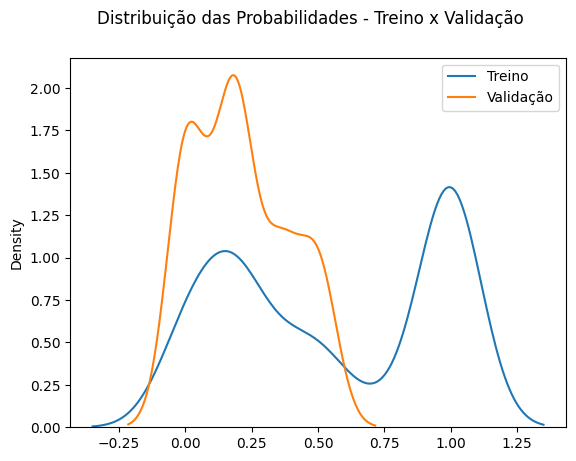

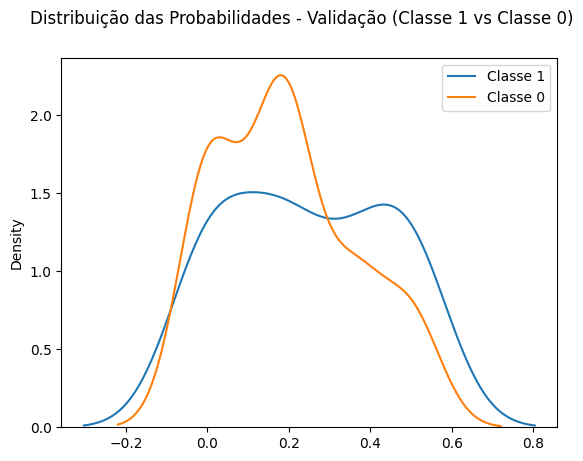

In [ ]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_treinado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

(<Axes: >,
 count    90.000000
 mean      0.210782
 std       0.176741
 min       0.000000
 25%       0.000000
 50%       0.194444
 75%       0.357143
 max       0.500000
 dtype: float64)

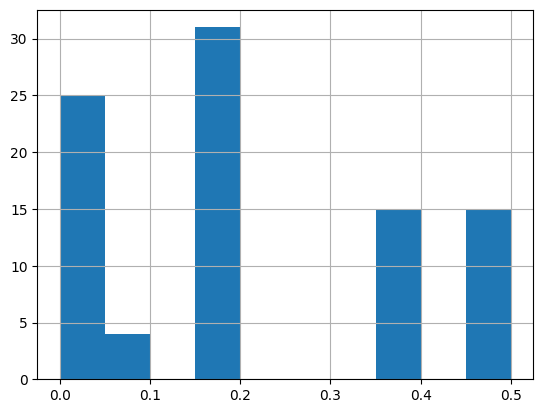

In [ ]:
pd.Series(probas).hist(), pd.Series(probas).describe()

# Redução de features

In [ ]:
# Importâncias
importancias = pd.Series(modelo_original.feature_importances_, index=X_train.columns)
importancias = importancias.sort_values(ascending=False)
importancias.head(15)


close_vs_adc_close_mean_geral            593.602402
adc_correl_com_principal_BEEF3           301.161100
dolar_trend                              168.918600
close_amplitude_norm_atr_principal        90.541520
adc_correl_com_principal_BRFS3            84.953588
macd_signal_mean                          59.739935
macd_signal_ultimo_norm_atr_principal     52.640001
adc_atr_pct_ultimo_BEEF3                  48.530800
tr_std                                    32.812199
ibov_trend                                23.509001
macd_ultimo_norm_atr_principal            22.926100
adc_rsi_ultimo_JBSS3                      22.244801
close_trend                               17.977699
adc_correl_com_principal_JBSS3            16.024582
correl_papel_ibov                         11.575900
dtype: float64

In [ ]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo, _ = criar_e_treinar_modelo_final_com_es_e_calib(
                X_train[colunas_selecionadas], y_train,
                fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
                estrategia_calibracao_cv='prefit'
            )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

In [ ]:
resultados_precisao

{5: np.float64(nan),
 10: np.float64(nan),
 15: np.float64(nan),
 20: np.float64(nan),
 25: np.float64(0.0),
 30: np.float64(0.2811688311688311),
 35: np.float64(nan),
 40: np.float64(nan),
 45: np.float64(0.5968266852195424),
 50: np.float64(nan)}

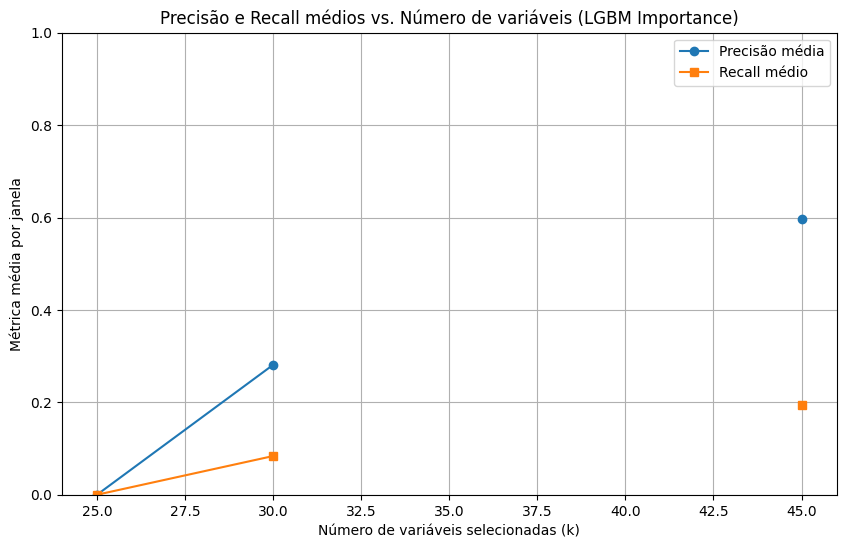

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (LGBM Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [ ]:
n_features = 55
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['close_vs_adc_close_mean_geral',
 'adc_correl_com_principal_BEEF3',
 'dolar_trend',
 'close_amplitude_norm_atr_principal',
 'adc_correl_com_principal_BRFS3',
 'macd_signal_mean',
 'macd_signal_ultimo_norm_atr_principal',
 'adc_atr_pct_ultimo_BEEF3',
 'tr_std',
 'ibov_trend',
 'macd_ultimo_norm_atr_principal',
 'adc_rsi_ultimo_JBSS3',
 'close_trend',
 'adc_correl_com_principal_JBSS3',
 'correl_papel_ibov',
 'retorno_desde_mudanca_close',
 'beta_papel_ibov',
 'macd_std',
 'macd_hist_std_norm_atr_principal',
 'ibov_std',
 'retorno_desde_mudanca_ibov',
 'volume_mean',
 'adc_rsi_ultimo_BEEF3',
 'retorno_desde_mudanca_dolar',
 'adc_macd_hist_ultimo_BRFS3',
 'rsi_std',
 'retorno_medio_pos',
 'close_amplitude',
 'close_min',
 'dias_queda_pct',
 'dias_alta_pct',
 'retorno_acumulado',
 'retorno_std',
 'retorno_mean',
 'mm5_vs_mm20',
 'close_vs_mm20',
 'close_ult_vs_mm_janela',
 'close_dist_min',
 'volume_ult_vs_mean',
 'rsi_ultimo',
 'macd_signal_std',
 'atr_pct_ultimo',
 'volume_trend',
 'volu

In [ ]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [ ]:
modelo_reduzido, _ = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train_reduzido, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'    
)

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

Dividindo Super Treino (485 amostras):
  - Treino Base LGBM: 388 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 97 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[15]	valid_0's auc: 0.662662	valid_0's binary_logloss: 0.631605
Treinamento LGBM concluído. Melhor iteração: 15

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (97 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.814
AUC na validação: 0.541
Diferença AUC (Treino - Validação): 0.274
PROVÁVEL OVERFITTING
PR AUC no treino: 0.505
PR AUC na validação: 0.428
Diferença PR AUC (Treino - Validação): 0.076
F1 Score no treino: 0.492
F1 Score na validação: 0.166


(np.float64(0.8141250496064021),
 np.float64(0.5406060128178298),
 np.float64(0.27351903678857226),
 np.float64(0.5045786748870741),
 np.float64(0.42818864226659953),
 np.float64(0.4923051803128624),
 np.float64(0.16609950196239195))

Avaliar e logar modelo
MLflow Run ID: b6c57f7fee6d4037bfafea7b5b8f712b para MRFG3.SA_6dias_x_0.07val_5dias_alvo
AUC no treino: 0.790
AUC na validação: 0.562

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.814
  Precisão média (em 442 janelas com previsão positiva): 0.379
  Recall médio: 0.848

Calibrando thresholds para precisão mínima de 0.60...
Nenhum threshold atendeu à precisão mínima de 0.60. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 52 janelas com previsão positiva): 0.437
Recall médio: 0.119
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 13
Modelo MRFG3.SA_6dias_x_0.07val_5dias_alvo salvo na run b6c57f7fee6d4037bfafea7b5b8f712b


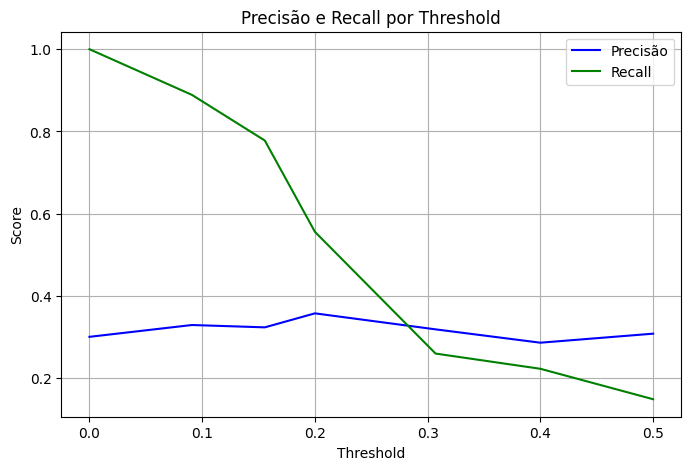

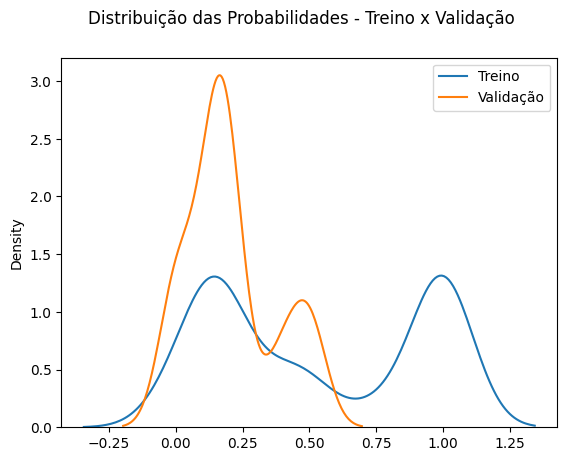

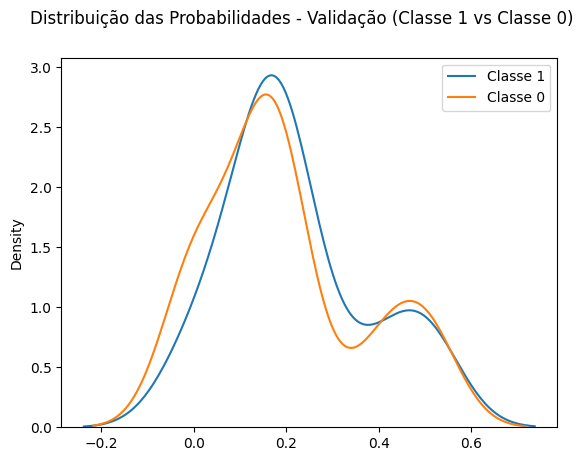

In [ ]:
precisao_minima = 0.6
recall_minimo = None
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

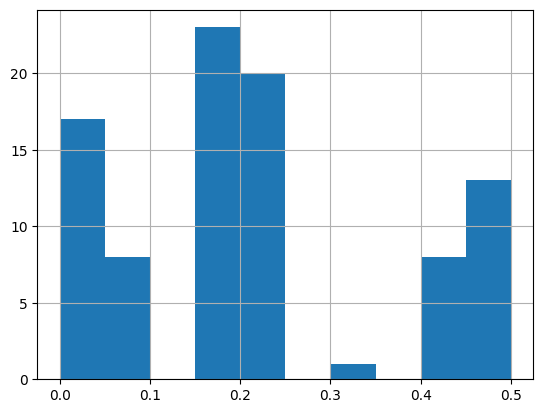

In [ ]:
pd.Series(probas).hist()

In [ ]:
pd.Series(probas).describe()

count    90.000000
mean      0.203468
std       0.161489
min       0.000000
25%       0.090909
50%       0.155556
75%       0.200000
max       0.500000
dtype: float64